In [1]:
import pandas as pd

df = pd.read_csv("../data/processed/titles_clean.csv")
print(df.shape)
print(df["media_type"].value_counts())
df.head()


(1908, 21)
media_type
movie    971
tv       937
Name: count, dtype: int64


,id,media_type,title,release_date,release_year,vote_average,vote_count,popularity,original_language,genres,...,runtime,content_rating,overview,source,extracted_at,date_added,decade,is_recent,rating_tier,runtime_bucket
0,1236045,movie,Animals,2026-10-09,2026,6.973,642,107.0333,en,Thriller|Drama|Action|Crime,...,106.0,NaN,When the son of an L.A. mayoral candidate is k...,tmdb,2026-10-30T13:23:28+00:00,NaN,2020,True,Medium,60-119 min
1,1780005,movie,Surviving Hurricane Otis,2026-10-23,2026,7.200,68,100.4734,es,Drama,...,97.0,NaN,Two estranged brothers struggle to survive Hur...,tmdb,2026-10-30T13:23:28+00:00,NaN,2020,True,Medium,60-119 min
2,1453407,movie,Gajab Raat,2026-10-23,2026,4.400,9,102.8935,hi,Thriller|Crime,...,124.0,NaN,"A corrupt, troubled cop's night spirals out of...",tmdb,2026-10-30T13:23:28+00:00,NaN,2020,True,Low,120-179 min
3,361743,movie,Top Gun: Maverick,2022-05-21,2022,8.158,11818,54.3768,en,Action|Drama,...,131.0,NaN,After more than thirty years of service as one...,tmdb,2026-10-30T13:23:28+00:00,NaN,2020,True,High,120-179 min
4,4488,movie,Friday the 13th,1980-05-09,1980,6.401,3562,56.6821,en,Horror,...,95.0,NaN,Camp counselors are stalked and murdered by an...,tmdb,2026-10-30T13:23:28+00:00,NaN,1980,False,Medium,60-119 min


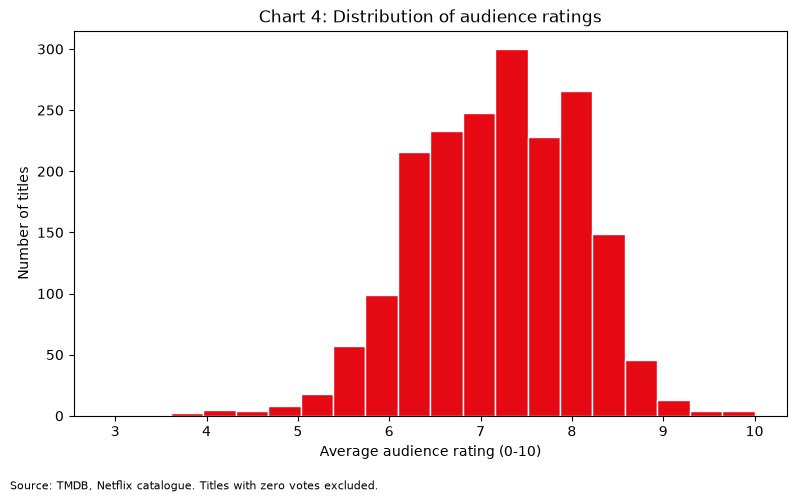

In [2]:
import matplotlib.pyplot as plt

# Titles with zero votes have no real average, so leave them out.
rated = df[df["vote_count"] > 0]

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(rated["vote_average"].dropna(), bins=20, color="#E50914", edgecolor="white")
ax.set_title("Chart 4: Distribution of audience ratings")
ax.set_xlabel("Average audience rating (0-10)")
ax.set_ylabel("Number of titles")
fig.text(0.01, 0.01, "Source: TMDB, Netflix catalogue. Titles with zero votes excluded.", fontsize=8)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("../figures/04_rating_histogram.png", dpi=150)
plt.show()


Most titles are rated between 6 and 8.5, peaking around 7.2. Very few titles fall below 5, so the TMDB catalogue is generally well rated.


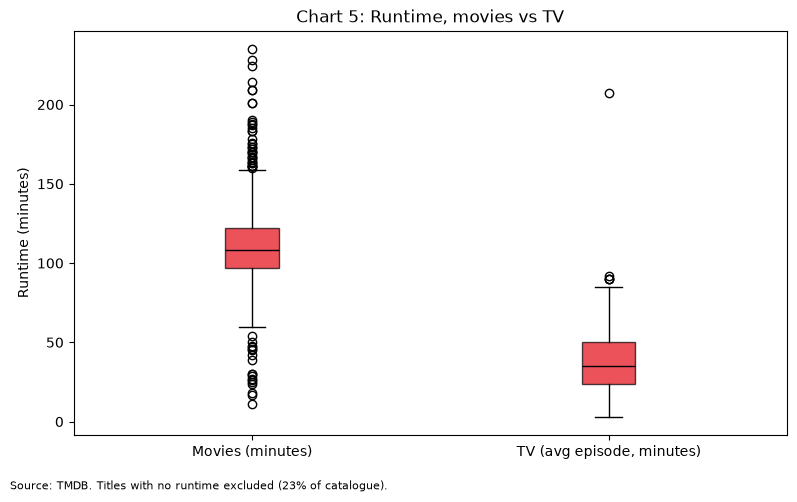

In [3]:
import matplotlib.pyplot as plt

# Only titles that have a runtime. Missing runtime stays excluded, never filled with 0.
has_runtime = df.dropna(subset=["runtime"])

movies = has_runtime.loc[has_runtime["media_type"] == "movie", "runtime"]
tv = has_runtime.loc[has_runtime["media_type"] == "tv", "runtime"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([movies, tv], tick_labels=["Movies (minutes)", "TV (avg episode, minutes)"],
           patch_artist=True, boxprops=dict(facecolor="#E50914", alpha=0.7),
           medianprops=dict(color="black"))
ax.set_title("Chart 5: Runtime, movies vs TV")
ax.set_ylabel("Runtime (minutes)")
fig.text(0.01, 0.01, "Source: TMDB. Titles with no runtime excluded (23% of catalogue).", fontsize=8)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("../figures/05_runtime_boxplot.png", dpi=150)
plt.show()


Movies have a median runtime of about 108 minutes, while a typical TV episode runs about 35 minutes, so the two should not be compared directly. Movies also have many long outliers above 160 minutes.

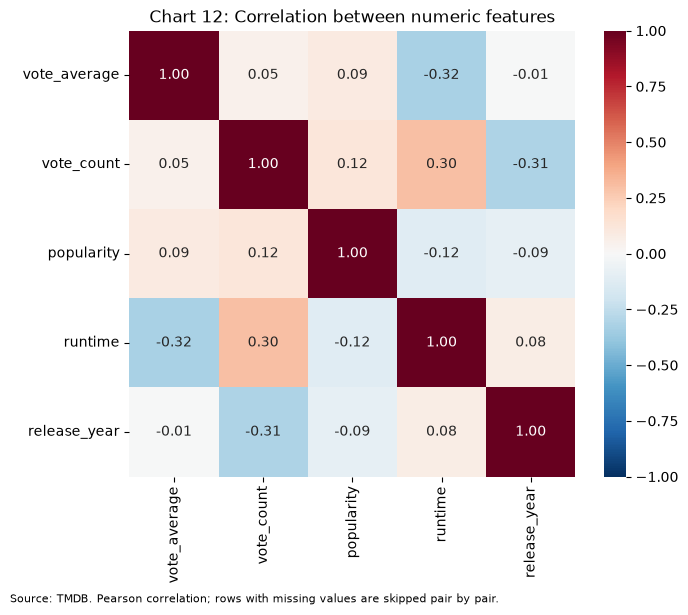

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric = df[["vote_average", "vote_count", "popularity", "runtime", "release_year"]]
corr = numeric.corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Chart 12: Correlation between numeric features")
fig.text(0.01, 0.01, "Source: TMDB. Pearson correlation; rows with missing values are skipped pair by pair.", fontsize=8)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("../figures/12_correlation_heatmap.png", dpi=150)
plt.show()


Runtime has the strongest relationship with rating (-0.32), so longer titles tend to be rated slightly lower. Other correlations are weak, and correlation does not show cause.

In [5]:
quality = pd.read_csv("../data/processed/data_quality_summary.csv")
quality


,metric,value
0,rows extracted,2000.0
1,exact duplicate rows removed,89.0
2,"same (id, media_type) same-title duplicates re...",3.0
3,rows passed validation,1908.0
4,rows rejected,0.0
5,missing % in id,0.0
6,missing % in media_type,0.0
7,missing % in title,0.0
8,missing % in release_date,0.0
9,missing % in release_year,0.0


Of 2,000 extracted rows, 92 were duplicates and none were rejected after validation. Runtime is missing for 23.4% of titles, and content rating is missing for all of them because TMDB does not provide it.